# 単語ラティス・仮名漢字変換・CRF vs MEMM・Pointwise 予測

書籍 第3章「系列ラベリング問題の解き方」（3-1-2 機械学習ベースの固有表現認識、3-2 形態素解析、3-2-3 機械学習ベースの形態素解析とラベルバイアス・点推定 (p.86, p.99)、関連論文 3章 7・8、練習問題 1・2）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、以下の 4 つを体験します。

1. **日本語単語分割の単語ラティス構築と Viterbi アルゴリズム (3-2)**: 最長一致法が失敗する曖昧文に対し、ノードコスト＋連接コストの最小化で大域最適解を求める。
2. **確率的モデルによる仮名漢字変換（3-2・関連論文 3章 7）**: 読み→漢字辞書からかな漢字ラティスを構築し、単語ユニグラム確率のみ vs 単語バイグラム言語モデル + Viterbi（N-best 候補列）で同音異義語を解消する。
3. **線形鎖 CRF vs MEMM とラベルバイアス問題（3-1-2 p.86・3-2-3 p.99）**: 同じ素性テンプレート・同じ正則化条件で両者を学習させ、局所正規化モデル (MEMM) の失敗と大域正規化 (CRF) による解消を確認する。
4. **点推定（Pointwise 予測）による形態素解析と部分的アノテーション適応（3-2-3・関連論文 3章 8）**: ラティスを使わず文字境界ごとに独立判定する手法と、専門複合語への部分的アノテーション適応・一貫性の注意点を確かめる。

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

---

## 1. 単語ラティスと Viterbi アルゴリズムによるコスト最小化 (3-2)

形態素解析器（MeCab や SudachiPy など）は、入力文字列に対して辞書から取り出せる全候補単語の有向非巡回グラフ（**単語ラティス**）を構築し、各単語の**生起コスト**（ノードコスト）と品詞間の**連接コスト**（エッジコスト）の合計が最小になる経路を **Viterbi アルゴリズム（動的計画法）** で求めます。

まずは「貪欲な前方最長一致法」が誤分割してしまう典型的な曖昧文に対して、Viterbi アルゴリズムがどのように正解経路を見つけるか確認しましょう。

In [2]:
# 辞書: 表層形 -> [(品詞, ノードコスト), ...]
LEXICON = {
    "ここ": [("名詞", 2.0)],
    "で": [("助詞", 1.0)],
    "は": [("助詞", 1.0)],
    "では": [("助詞", 1.5)],
    "はきもの": [("名詞", 1.2)],
    "きもの": [("名詞", 2.2)],
    "を": [("助詞", 0.8)],
    "ぬぐ": [("動詞", 1.5)],
    "にわ": [("名詞", 1.6), ("名-数詞", 1.9)],
    "に": [("助詞", 0.9)],
    "はにわ": [("名詞", 3.6)],
    "にわとり": [("名詞", 1.4)],
    "が": [("助詞", 0.8)],
    "いる": [("動詞", 1.4)],
    "はは": [("名詞", 1.6)],
    "ははは": [("感動詞", 3.2)],
    "はな": [("名詞", 1.5)],
    "すき": [("形容動詞", 1.4)],
}

# 品詞間の連接コスト: (前品詞, 現品詞) -> コスト
DEFAULT_EDGE = 4.0
TRANS_COST = {
    ("BOS", "名詞"): 0.5, ("BOS", "動詞"): 1.8, ("BOS", "感動詞"): 2.2,
    ("名詞", "助詞"): 0.4, ("名詞", "EOS"): 1.0, ("名詞", "名詞"): 2.4,
    ("助詞", "名詞"): 0.6, ("助詞", "動詞"): 0.7, ("助詞", "助詞"): 1.1,
    ("助詞", "形容動詞"): 0.6, ("助詞", "名-数詞"): 1.0,
    ("名-数詞", "名詞"): 0.9,
    ("動詞", "助詞"): 0.9, ("動詞", "EOS"): 0.4,
    ("感動詞", "名詞"): 3.2,
    ("形容動詞", "EOS"): 0.5,
}

def edge_cost(prev_pos, curr_pos):
    return TRANS_COST.get((prev_pos, curr_pos), DEFAULT_EDGE)

def greedy_longest_match(text, lexicon):
    tokens, i = [], 0
    while i < len(text):
        matched = None
        for j in range(len(text), i, -1):
            if text[i:j] in lexicon:
                matched = text[i:j]
                break
        if matched is None:
            tokens.append(text[i])
            i += 1
        else:
            tokens.append(matched)
            i += len(matched)
    return tokens

def build_lattice(text, lexicon):
    n = len(text)
    ends_at = [[] for _ in range(n + 1)]
    bos = (0, 0, 0, "<BOS>", "BOS", 0.0)
    ends_at[0].append(bos)
    nid = 1
    for s in range(n):
        for e in range(s + 1, n + 1):
            surf = text[s:e]
            if surf in lexicon:
                for pos, ncost in lexicon[surf]:
                    ends_at[e].append((nid, s, e, surf, pos, ncost))
                    nid += 1
    eos = (nid, n, n, "<EOS>", "EOS", 0.0)
    return bos, ends_at, eos

def viterbi_segment(text, lexicon=LEXICON):
    n = len(text)
    bos, ends_at, eos = build_lattice(text, lexicon)
    dp = {bos[0]: 0.0}
    bp = {bos[0]: None}
    node_map = {bos[0]: bos, eos[0]: eos}
    for t in range(1, n + 1):
        for node in ends_at[t]:
            nid, s, e, surf, pos, ncost = node
            node_map[nid] = node
            best_cost, best_prev = math.inf, None
            for pnode in ends_at[s]:
                pid = pnode[0]
                if pid not in dp:
                    continue
                cand = dp[pid] + edge_cost(pnode[4], pos) + ncost
                if cand < best_cost:
                    best_cost, best_prev = cand, pid
            if best_prev is not None:
                dp[nid] = best_cost
                bp[nid] = best_prev
    best_cost, best_prev = math.inf, None
    for pnode in ends_at[n]:
        pid = pnode[0]
        if pid in dp:
            cand = dp[pid] + edge_cost(pnode[4], "EOS")
            if cand < best_cost:
                best_cost, best_prev = cand, pid
    path = []
    cur = best_prev
    while cur is not None and cur != bos[0]:
        path.append(node_map[cur])
        cur = bp[cur]
    path.reverse()
    return path, best_cost, ends_at, dp

sentences = [
    "ここではきものをぬぐ",
    "にわにはにわにわとりがいる",
    "ははははながすき",
]
rows = []
for s in sentences:
    g = greedy_longest_match(s, LEXICON)
    path, total_cost, _, _ = viterbi_segment(s)
    rows.append({
        "入力文": s,
        "前方最長一致": " / ".join(g),
        "Viterbi最小コスト解": " / ".join(f"{nd[3]}({nd[4]})" for nd in path),
        "総コスト": round(total_cost, 2),
    })
pd.DataFrame(rows)

,入力文,前方最長一致,Viterbi最小コスト解,総コスト
0,ここではきものをぬぐ,ここ / では / きもの / を / ぬぐ,ここ(名詞) / で(助詞) / はきもの(名詞) / を(助詞) / ぬぐ(動詞),9.5
1,にわにはにわにわとりがいる,にわ / に / はにわ / にわとり / が / いる,にわ(名詞) / に(助詞) / は(助詞) / にわ(名-数詞) / にわとり(名詞) /...,14.4
2,ははははながすき,ははは / はな / が / すき,はは(名詞) / は(助詞) / はな(名詞) / が(助詞) / すき(形容動詞),9.3


前方最長一致法では「ここでは」「はにわ」「ははは」のように局所的に長い単語へ飛びついて不自然な分割になりますが、Viterbi アルゴリズムは文全体の累積コストを見て正しい分割を選びます。

「ここではきものをぬぐ」について、全経路列挙（総当たり）の上位候補および各文字位置の DP 表の中身を確認し、Viterbi 解が厳密な大域最小コスト経路と一致していることを確かめましょう。

In [3]:
def enumerate_all_paths(text, lexicon=LEXICON):
    n = len(text)
    results = []
    def dfs(pos, prev_pos, acc_nodes, node_sum, edge_sum):
        if pos == n:
            ec = edge_cost(prev_pos, "EOS")
            results.append((acc_nodes, node_sum, edge_sum + ec, node_sum + edge_sum + ec))
            return
        for end in range(pos + 1, n + 1):
            surf = text[pos:end]
            if surf in lexicon:
                for p, ncost in lexicon[surf]:
                    ec = edge_cost(prev_pos, p)
                    dfs(end, p, acc_nodes + [(surf, p)], node_sum + ncost, edge_sum + ec)
    dfs(0, "BOS", [], 0.0, 0.0)
    return sorted(results, key=lambda x: x[3])

target = "ここではきものをぬぐ"
all_paths = enumerate_all_paths(target)
top_rows = []
for rank, (nodes, n_sum, e_sum, tot) in enumerate(all_paths[:4], 1):
    top_rows.append({
        "順位": rank,
        "分割経路": " / ".join(f"{w}({p})" for w, p in nodes),
        "ノードコスト和": round(n_sum, 2),
        "連接コスト和": round(e_sum, 2),
        "総コスト": round(tot, 2),
    })
print(f"『{target}』のラティス全経路数: {len(all_paths)} 通り（上位4件）")
display(pd.DataFrame(top_rows))

_, _, ends_at, dp = viterbi_segment(target)
dp_rows = []
for t in range(1, len(target) + 1):
    for nid, s, e, surf, pos, ncost in ends_at[t]:
        if nid in dp:
            dp_rows.append({
                "終端位置 t": t, "範囲": f"[{s}:{e}]", "候補単語": surf,
                "品詞": pos, "ノードコスト": ncost, "累積最小コスト dp": round(dp[nid], 2)
            })
pd.DataFrame(dp_rows)

『ここではきものをぬぐ』のラティス全経路数: 3 通り（上位4件）


,順位,分割経路,ノードコスト和,連接コスト和,総コスト
0,1,ここ(名詞) / で(助詞) / はきもの(名詞) / を(助詞) / ぬぐ(動詞),6.5,3.0,9.5
1,2,ここ(名詞) / では(助詞) / きもの(名詞) / を(助詞) / ぬぐ(動詞),8.0,3.0,11.0
2,3,ここ(名詞) / で(助詞) / は(助詞) / きもの(名詞) / を(助詞) / ぬぐ(動詞),8.5,4.1,12.6


,終端位置 t,範囲,候補単語,品詞,ノードコスト,累積最小コスト dp
0,2,[0:2],ここ,名詞,2.0,2.5
1,3,[2:3],で,助詞,1.0,3.9
2,4,[2:4],では,助詞,1.5,4.4
3,4,[3:4],は,助詞,1.0,6.0
4,7,[3:7],はきもの,名詞,1.2,5.7
5,7,[4:7],きもの,名詞,2.2,7.2
6,8,[7:8],を,助詞,0.8,6.9
7,10,[8:10],ぬぐ,動詞,1.5,9.1


---

## 2. 確率的モデルによる仮名漢字変換（かな漢字ラティスと同音異義語解消、3-2・関連論文 3章 7）

関連論文 3章 7（森信介ほか, 1999「確率的モデルによる仮名漢字変換」）では、第 1 節の形態素解析の枠組みを応用し、ひらがな列 $Y$ から単語ラティス（かな漢字ラティス）を構築して事後確率 $P(W \mid Y) \propto P(W) P(Y \mid W)$ を最大化する単語列 $W$（すなわちコスト $-\log P(W)$ の最小経路）を Viterbi アルゴリズムで求める定式化が示されています。

- **単語ユニグラムモデルのみ**: 各候補語の事前生起確率 $\log P(w_t)$ だけを使うと、文脈を無視して単に一般頻度の高い漢字（「記者」「高尚」「気候」「橋」など）ばかりを選んでしまいます。
- **単語バイグラム言語モデル + Viterbi**: 隣接語の遷移確率 $\log P(w_t \mid w_{t-1})$ をエッジコストとして組み合わせることで、「貴社の記者が汽車で帰社した」「交渉に臨む」「会社の機構」「橋の上で箸を使う」といった同音異義語を文脈から正しく解消でき、上位 N-best 候補列も効率的に列挙できます。

In [4]:
# 読み -> [(表記, unigram logP <= 0), ...]
KKC_LEXICON = {
    "きしゃ": [("記者", -2.1), ("帰社", -2.8), ("汽車", -3.0), ("貴社", -3.2)],
    "の": [("の", -0.5)],
    "が": [("が", -0.6)],
    "で": [("で", -0.7)],
    "した": [("した", -0.9)],
    "こうしょう": [("高尚", -2.2), ("考証", -2.6), ("交渉", -2.8)],
    "に": [("に", -0.6)],
    "のぞむ": [("望む", -1.9), ("臨む", -2.7)],
    "かいしゃ": [("会社", -1.5), ("解釈", -2.6)],
    "きこう": [("気候", -2.1), ("寄稿", -2.6), ("機構", -2.9)],
    "はし": [("橋", -2.2), ("端", -2.4), ("箸", -2.9)],
    "うえ": [("上", -1.4)],
    "を": [("を", -0.6)],
    "つかう": [("使う", -1.6)],
}

# 単語バイグラム対数遷移確率 log P(w_t | w_{t-1}) <= 0（自然な連接ほど 0 に近く、不自然な連接は -3.5）
DEFAULT_BG_LOGP = -3.5
BIGRAM_LOGP = {
    ("BOS", "貴社"): -0.3, ("貴社", "の"): -0.2, ("の", "記者"): -0.4, ("記者", "が"): -0.3,
    ("が", "汽車"): -0.7, ("汽車", "で"): -0.2, ("で", "帰社"): -0.3, ("帰社", "した"): -0.2, ("した", "EOS"): -0.2,
    ("BOS", "交渉"): -0.5, ("交渉", "に"): -0.2, ("に", "臨む"): -0.2, ("臨む", "EOS"): -0.3,
    ("BOS", "会社"): -0.4, ("会社", "の"): -0.2, ("の", "機構"): -0.4, ("機構", "EOS"): -0.3,
    ("BOS", "橋"): -0.6, ("橋", "の"): -0.3, ("の", "上"): -0.2, ("上", "で"): -0.3,
    ("で", "箸"): -0.5, ("箸", "を"): -0.2, ("を", "使う"): -0.2, ("使う", "EOS"): -0.3,
    # 一部の文脈的にあり得る2位候補用遷移
    ("が", "記者"): -1.4, ("の", "気候"): -1.8, ("の", "寄稿"): -2.2, ("に", "望む"): -1.9,
    ("で", "橋"): -2.1, ("で", "端"): -2.2, ("箸", "を"): -0.2,
}

def kkc_viterbi(kana, use_bigram=True):
    """かな漢字ラティス上の Viterbi DP で最小コスト (-log P) の変換列を求める"""
    n = len(kana)
    ends_at = [[] for _ in range(n + 1)]
    bos = (0, 0, "<BOS>", 0.0)
    ends_at[0].append(bos)
    nid = 1
    for s in range(n):
        for e in range(s + 1, n + 1):
            sub = kana[s:e]
            if sub in KKC_LEXICON:
                for surf, u_lp in KKC_LEXICON[sub]:
                    ends_at[e].append((nid, s, surf, -u_lp))
                    nid += 1
    dp, bp, nmap = {0: 0.0}, {0: None}, {0: bos}
    for t in range(1, n + 1):
        for node in ends_at[t]:
            id_, s, surf, ncost = node
            nmap[id_] = node
            best_c, best_p = math.inf, None
            for pn in ends_at[s]:
                pid = pn[0]
                if pid not in dp:
                    continue
                prev_w = "BOS" if pid == 0 else pn[2]
                ecost = -BIGRAM_LOGP.get((prev_w, surf), DEFAULT_BG_LOGP) if use_bigram else 0.0
                cand = dp[pid] + ecost + ncost
                if cand < best_c:
                    best_c, best_p = cand, pid
            if best_p is not None:
                dp[id_], bp[id_] = best_c, best_p
    best_c, best_p = math.inf, None
    for pn in ends_at[n]:
        pid = pn[0]
        if pid in dp:
            ecost = -BIGRAM_LOGP.get((pn[2], "EOS"), DEFAULT_BG_LOGP) if use_bigram else 0.0
            cand = dp[pid] + ecost
            if cand < best_c:
                best_c, best_p = cand, pid
    words = []
    cur = best_p
    while cur is not None and cur != 0:
        words.append(nmap[cur][2])
        cur = bp[cur]
    words.reverse()
    return words, -best_c  # 対数確率 (高いほど良い)

def kkc_nbest(kana, nbest=3):
    n = len(kana)
    paths = []
    def dfs(pos, prev_w, acc, lp):
        if pos == n:
            paths.append((acc, lp + BIGRAM_LOGP.get((prev_w, "EOS"), DEFAULT_BG_LOGP)))
            return
        for e in range(pos + 1, n + 1):
            sub = kana[pos:e]
            if sub in KKC_LEXICON:
                for surf, u_lp in KKC_LEXICON[sub]:
                    b_lp = BIGRAM_LOGP.get((prev_w, surf), DEFAULT_BG_LOGP)
                    dfs(e, surf, acc + [surf], lp + u_lp + b_lp)
    dfs(0, "BOS", [], 0.0)
    paths.sort(key=lambda x: x[1], reverse=True)
    return paths[:nbest]

kkc_inputs = [
    "きしゃのきしゃがきしゃできしゃした",
    "こうしょうにのぞむ",
    "かいしゃのきこう",
    "はしのうえではしをつかう",
]
kkc_rows = []
for kana in kkc_inputs:
    u_words, u_lp = kkc_viterbi(kana, use_bigram=False)
    b_words, b_lp = kkc_viterbi(kana, use_bigram=True)
    kkc_rows.append({
        "入力ひらがな": kana,
        "ユニグラムのみ": "".join(u_words),
        "ユニグラム logP": round(u_lp, 2),
        "バイグラム+Viterbi": "".join(b_words),
        "バイグラム logP": round(b_lp, 2),
    })

display(pd.DataFrame(kkc_rows))

print("=== バイグラム言語モデルによる N-best 変換候補 (Top 3) ===")
for target_k in ["きしゃのきしゃがきしゃできしゃした", "はしのうえではしをつかう"]:
    print(f"\n入力: {target_k}")
    for rk, (wds, lp) in enumerate(kkc_nbest(target_k, nbest=3), 1):
        print(f"  {rk}位 (logP={lp:6.2f}): {' / '.join(wds)}")

,入力ひらがな,ユニグラムのみ,ユニグラム logP,バイグラム+Viterbi,バイグラム logP
0,きしゃのきしゃがきしゃできしゃした,記者の記者が記者で記者した,-11.1,貴社の記者が汽車で帰社した,-16.6
1,こうしょうにのぞむ,高尚に望む,-4.7,交渉に臨む,-7.3
2,かいしゃのきこう,会社の気候,-4.1,会社の機構,-6.2
3,はしのうえではしをつかう,橋の上で橋を使う,-9.2,橋の上で箸を使う,-12.5


=== バイグラム言語モデルによる N-best 変換候補 (Top 3) ===

入力: きしゃのきしゃがきしゃできしゃした
  1位 (logP=-16.60): 貴社 / の / 記者 / が / 汽車 / で / 帰社 / した
  2位 (logP=-19.70): 貴社 / の / 記者 / が / 記者 / で / 帰社 / した
  3位 (logP=-22.00): 記者 / の / 記者 / が / 汽車 / で / 帰社 / した

入力: はしのうえではしをつかう
  1位 (logP=-12.50): 橋 / の / 上 / で / 箸 / を / 使う
  2位 (logP=-16.70): 橋 / の / 上 / で / 橋 / を / 使う
  3位 (logP=-17.00): 橋 / の / 上 / で / 端 / を / 使う


- **ユニグラムのみ**: 「きしゃ」では毎回単体頻度が最も高い「記者」を選び、「記者の記者が記者で記者した」のように意味をなさない変換になります。「こうしょうにのぞむ」「かいしゃのきこう」「はしのうえではしをつかう」でも同様に、文脈と無関係な高頻度語が選ばれます。
- **バイグラム + Viterbi**: 単語間の連接確率を加えることで、文全体の同時確率が最大となる「貴社 / の / 記者 / が / 汽車 / で / 帰社 / した」「交渉 / に / 臨む」「会社 / の / 機構」「橋 / の / 上 / で / 箸 / を / 使う」を同音異義語から正確に選べることがわかります。また N-best 候補列を出せば、変換候補一覧のランキング提示にも対応できます。

---

## 3. 線形鎖 CRF vs MEMM とラベルバイアス問題（3-1-2 p.86・3-2-3 p.99）

書籍 3-1-2 (p.86) では、CRF (Conditional Random Field) の利点として **「（MEMM などの局所正規化モデルと比べて）ラベルバイアスの影響を受けにくい」** ことが挙げられています。

### なぜラベルバイアス (Label Bias) が起きるのか？
長さ 2 の系列 $x = (x_1, x_2)$ にタグ列 $y = (y_1, y_2)$ を振る例を考えます。
遷移ルールとして、次の 3 本のパスのみが許されるとします（Lafferty et al., 2001 と同型の分岐非対称トポロジー）。
- 状態 `B-P` からは `I-P` のみへ遷移可能（**分岐数 = 1**）
- 状態 `B-Q` からは `I-Q` または `O` へ遷移可能（**分岐数 = 2**）

訓練データは次の 3 パターンだけで構成されているとします（**矛盾ゼロ・決定的な正解**が存在します）。
- `("新", "宿") -> ("B-P", "I-P")` が **45 回**
- `("新", "橋") -> ("B-Q", "I-Q")` が **20 回**
- `("新", "店") -> ("B-Q", "O")`   が **20 回**

ここで **MEMM（各時刻で独立に softmax 正規化）** と **線形鎖 CRF（系列全体で 1 回だけ大域正規化）** に、**完全に同じ素性テンプレート・完全に同じ正則化パラメータ**を与えて最尤学習させてみます。

In [5]:
ALLOWED_PATHS = [
    ("B-P", "I-P"),
    ("B-Q", "I-Q"),
    ("B-Q", "O"),
]
NEXT_STATES = {
    "BOS": ["B-P", "B-Q"],
    "B-P": ["I-P"],        # 分岐数 1（遷移先が1つしかない）
    "B-Q": ["I-Q", "O"],  # 分岐数 2
}

train_corpus = (
    [(("新", "宿"), ("B-P", "I-P"))] * 45 +
    [(("新", "橋"), ("B-Q", "I-Q"))] * 20 +
    [(("新", "店"), ("B-Q", "O"))] * 20
)

def step_features(y_prev, y_curr, x_curr, t):
    return [f"TRANS:{y_prev}->{y_curr}", f"EMIT:t{t}:{y_curr}:{x_curr}"]

all_feat_names = sorted({
    f
    for x_seq, _ in train_corpus
    for y1, y2 in ALLOWED_PATHS
    for f in (step_features("BOS", y1, x_seq[0], 1) + step_features(y1, y2, x_seq[1], 2))
})
feat_idx = {f: i for i, f in enumerate(all_feat_names)}

def phi_vec(y_prev, y_curr, x_curr, t):
    v = np.zeros(len(feat_idx))
    for f in step_features(y_prev, y_curr, x_curr, t):
        if f in feat_idx:
            v[feat_idx[f]] = 1.0
    return v

def logsumexp(a):
    m = np.max(a)
    return m + np.log(np.sum(np.exp(a - m)))

L2_REG = 0.05  # 両モデルで同一のL2正則化を使用

# --- A. MEMM（各時刻で条件付き確率を局所正規化）---
def memm_nll(w):
    loss = 0.5 * L2_REG * np.sum(w ** 2)
    for x_seq, (y1, y2) in train_corpus:
        cands1 = NEXT_STATES["BOS"]
        scores1 = np.array([w @ phi_vec("BOS", c, x_seq[0], 1) for c in cands1])
        loss -= scores1[cands1.index(y1)] - logsumexp(scores1)
        cands2 = NEXT_STATES[y1]
        scores2 = np.array([w @ phi_vec(y1, c, x_seq[1], 2) for c in cands2])
        loss -= scores2[cands2.index(y2)] - logsumexp(scores2)
    return loss

# --- B. 線形鎖 CRF（系列全体で1回だけ大域正規化）---
def crf_nll(w):
    loss = 0.5 * L2_REG * np.sum(w ** 2)
    for x_seq, y_gold in train_corpus:
        path_scores = np.array([
            w @ (phi_vec("BOS", y1, x_seq[0], 1) + phi_vec(y1, y2, x_seq[1], 2))
            for y1, y2 in ALLOWED_PATHS
        ])
        loss -= path_scores[ALLOWED_PATHS.index(y_gold)] - logsumexp(path_scores)
    return loss

w0 = np.zeros(len(feat_idx))
w_memm = minimize(memm_nll, w0, method="BFGS").x
w_crf = minimize(crf_nll, w0, method="BFGS").x

def predict_memm_probs(w, x_seq):
    s1 = {c: w @ phi_vec("BOS", c, x_seq[0], 1) for c in NEXT_STATES["BOS"]}
    lse1 = logsumexp(list(s1.values()))
    p1 = {c: float(np.exp(v - lse1)) for c, v in s1.items()}
    out = {}
    for y1, y2 in ALLOWED_PATHS:
        s2 = [w @ phi_vec(y1, c, x_seq[1], 2) for c in NEXT_STATES[y1]]
        lse2 = logsumexp(s2)
        p2 = float(np.exp((w @ phi_vec(y1, y2, x_seq[1], 2)) - lse2))
        out[(y1, y2)] = (p1[y1], p2, p1[y1] * p2)
    return out

def predict_crf_probs(w, x_seq):
    scores = [w @ (phi_vec("BOS", y1, x_seq[0], 1) + phi_vec(y1, y2, x_seq[1], 2)) for y1, y2 in ALLOWED_PATHS]
    lse = logsumexp(scores)
    return {(y1, y2): (float(sc), float(np.exp(sc - lse))) for (y1, y2), sc in zip(ALLOWED_PATHS, scores)}

def viterbi_crf(w, x_seq):
    """Viterbi アルゴリズムで CRF の最尤系列を求める（全列挙と同じ結果になる）"""
    dp1 = {y1: w @ phi_vec("BOS", y1, x_seq[0], 1) for y1 in NEXT_STATES["BOS"]}
    best_score, best_path = -math.inf, None
    for y1, s1 in dp1.items():
        for y2 in NEXT_STATES[y1]:
            cand = s1 + (w @ phi_vec(y1, y2, x_seq[1], 2))
            if cand > best_score:
                best_score, best_path = cand, (y1, y2)
    return best_path, best_score

gold_map = {
    ("新", "宿"): ("B-P", "I-P"),
    ("新", "橋"): ("B-Q", "I-Q"),
    ("新", "店"): ("B-Q", "O"),
}
eval_rows = []
for x_seq, gold_pair in gold_map.items():
    mp = predict_memm_probs(w_memm, x_seq)
    cp = predict_crf_probs(w_crf, x_seq)
    pred_m = max(mp, key=lambda k: mp[k][2])
    pred_c, _ = viterbi_crf(w_crf, x_seq)
    eval_rows.append({
        "入力": "".join(x_seq),
        "正解タグ": str(gold_pair),
        "MEMM予測": f"{pred_m} ({'○' if pred_m == gold_pair else '×'})",
        "MEMM確率": round(mp[pred_m][2], 3),
        "CRF(Viterbi)予測": f"{pred_c} ({'○' if pred_c == gold_pair else '×'})",
        "CRF確率": round(cp[pred_c][1], 3),
    })
display(pd.DataFrame(eval_rows))

acc_memm = np.mean([max(predict_memm_probs(w_memm, x), key=lambda k: predict_memm_probs(w_memm, x)[k][2]) == y for x, y in train_corpus])
acc_crf = np.mean([viterbi_crf(w_crf, x)[0] == y for x, y in train_corpus])
print(f"訓練データ全体の精度 -> MEMM: {acc_memm:.3f} vs CRF: {acc_crf:.3f}")

,入力,正解タグ,MEMM予測,MEMM確率,CRF(Viterbi)予測,CRF確率
0,新宿,"('B-P', 'I-P')","('B-P', 'I-P') (○)",0.529,"('B-P', 'I-P') (○)",0.996
1,新橋,"('B-Q', 'I-Q')","('B-P', 'I-P') (×)",0.529,"('B-Q', 'I-Q') (○)",0.991
2,新店,"('B-Q', 'O')","('B-P', 'I-P') (×)",0.529,"('B-Q', 'O') (○)",0.991


訓練データ全体の精度 -> MEMM: 0.529 vs CRF: 1.000


### なぜ MEMM は `("新", "橋")` で負けたのか？（確率の中身とグラフで確認）

`("新", "橋")` を入力したときの各候補パスの局所遷移確率 (MEMM) と大域スコア・確率 (CRF) を並べて比較します。

,候補パス,MEMM P(y1|新),"MEMM P(y2|y1,橋)",MEMM 総確率 P1×P2,CRF 経路スコア S,CRF 総確率 exp(S)/Z
0,B-P -> I-P,0.5294,1.0000,0.5294,-1.777,0.0048
1,B-Q -> I-Q,0.4706,0.9937,0.4676,3.550,0.9908
2,B-Q -> O,0.4706,0.0063,0.0030,-1.873,0.0044


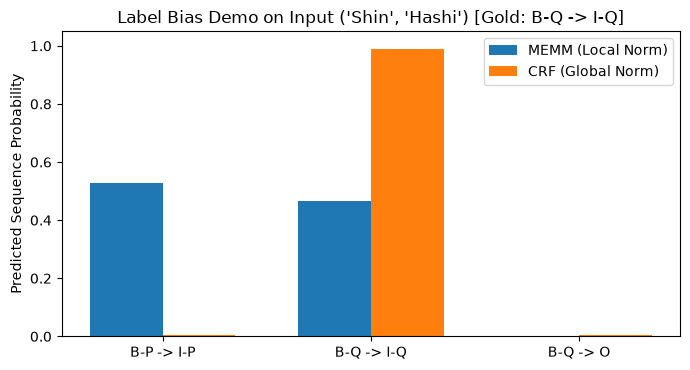

In [6]:
target_x = ("新", "橋")
mp = predict_memm_probs(w_memm, target_x)
cp = predict_crf_probs(w_crf, target_x)

detail_rows = []
for path in ALLOWED_PATHS:
    p1, p2, p_memm = mp[path]
    score_crf, p_crf = cp[path]
    detail_rows.append({
        "候補パス": f"{path[0]} -> {path[1]}",
        "MEMM P(y1|新)": round(p1, 4),
        "MEMM P(y2|y1,橋)": round(p2, 4),
        "MEMM 総確率 P1×P2": round(p_memm, 4),
        "CRF 経路スコア S": round(score_crf, 3),
        "CRF 総確率 exp(S)/Z": round(p_crf, 4),
    })
display(pd.DataFrame(detail_rows))

labels_en = [f"{p[0]} -> {p[1]}" for p in ALLOWED_PATHS]
memm_vals = [mp[p][2] for p in ALLOWED_PATHS]
crf_vals = [cp[p][1] for p in ALLOWED_PATHS]

x_pos = np.arange(len(labels_en))
width = 0.35
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(x_pos - width / 2, memm_vals, width, label="MEMM (Local Norm)")
ax.bar(x_pos + width / 2, crf_vals, width, label="CRF (Global Norm)")
ax.set_xticks(x_pos)
ax.set_xticklabels(labels_en)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Predicted Sequence Probability")
ax.set_title("Label Bias Demo on Input ('Shin', 'Hashi') [Gold: B-Q -> I-Q]")
ax.legend()
plt.tight_layout()
plt.show()

### ポイントの整理

- **MEMM の罠（ラベルバイアス）**: 時刻 2 の確率 $P(y_2 \mid y_1, x_2)$ を「その遷移元 $y_1$ から出られる候補だけ」で局所正規化するため、遷移先が 1 つしかない `B-P` では観測語が「橋」であっても必ず $P(\text{I-P} \mid \text{B-P}, \text{"橋"}) = 1.000$ になってしまいます。結果として、時刻 1 で `45 > 40` の頻度差から `B-P` が少し優位になると、後続の強力な観測情報「橋」を使っても挽回できなくなります。
- **CRF の解決策**: 全パスまとめて 1 つの分配関数 $Z(x)$ で大域正規化するため、各時刻の素性スコア（例：「橋」と `I-Q` の強い共起重み）を系列全体のスコアに直接加算でき、ラベルバイアスを回避して正しいパス `B-Q -> I-Q` を選べます。
- **Viterbi デコーディングとの相性**: 大域正規化モデルの最尤系列探索 ($\arg\max_y \sum_t \theta^\top \phi(y_{t-1}, y_t, x_t)$) は、第1節で実装した形態素解析のコスト最小化と数学的に同型の動的計画法（Viterbi アルゴリズム）で効率よく解けます。

---

## 4. 点推定（Pointwise 予測）による形態素解析と部分的アノテーション適応（3-2-3・関連論文 3章 8）

書籍 3-2-3 および関連論文 3章 8（Neubig et al., ACL-HLT 2011「*Pointwise Prediction for Robust, Adaptable Japanese Morphological Analysis*」、KyTea）では、第 1〜3 節のようなラティス探索や大域的系列モデリングを一切使わず、**文字と文字の間の各境界位置 $i \in \{1, \dots, n-1\}$ ごとに独立して「切る (`1`) / 切らない (`0`)」を 2 値分類する点推定**（Pointwise 予測）が提案されています。

Pointwise アプローチの大きな利点は、**文全体すべての単語境界にアノテーションを付ける必要がなく、着目したい語や誤りやすい箇所の数境界だけに `0/1` ラベルを付けた「部分的アノテーション (Partial Annotation)」をそのまま訓練データに追加できる**ことです。

ここでは：
1. 一般的な単語分割済みコーパス（20 文）で学習した Pointwise 分割器 (`LogisticRegression`) が、未見の医療・専門複合語（「抗凝固薬」「心房細動」「せん妄」「じょく瘡」「磁気共鳴」）を細かく誤分割してしまうことを確認します。
2. 専門複合語の周辺だけに境界ラベル（`|` = 切る、` - ` = 切らない）を付けた**部分的アノテーション 10 例**を追加学習させたとき、テスト文の境界 F1 と専門複合語の完全一致率がどう変化するか比較します。
3. あわせて関連論文 3章 8 で指摘されている「**大域制約や完全な辞書マッチを行わないため、周囲の文脈次第で同じ文字列の境界判断が揺れる可能性**」も確認します。

=== ドメインテスト文（5文・専門複合語 6 箇所）での評価比較 ===


,訓練設定,学習境界数,境界 Precision,境界 Recall,境界 F1,専門複合語 一致率
0,ベース一般コーパスのみ,270,0.816,0.952,0.879,0.0
1,+ 部分的アノテーション (10文),323,1.000,0.976,0.988,1.0


,正解分割,ベースのみ予測,部分アノテ適応後
0,新しい / 抗凝固薬 / が / 臨床 / で / 注目 / されている / 。,新しい / 抗凝 / 固薬 / が / 臨床 / で / 注目 / されている / 。,新しい / 抗凝固薬 / が / 臨床 / で / 注目 / されている / 。
1,心房細動 / の / 患者 / に / 抗凝固薬 / を / 使う / 。,心房 / 細動 / の / 患者 / に / 抗凝 / 固薬 / を / 使う / 。,心房細動 / の / 患者 / に / 抗凝固薬 / を / 使う / 。
2,入院 / 中 / の / せん妄 / を / 防ぐ / ケア / が / 進む / 。,入院中 / のせ / ん / 妄 / を / 防ぐ / ケア / が / 進む / 。,入院中 / の / せん妄 / を / 防ぐ / ケア / が / 進む / 。
3,じょく瘡 / の / 予防 / に / 定期 / 的 / な / 体位 / 変換 / を /...,じょ / く / 瘡 / の / 予防 / に / 定期 / 的 / な / 体位 / 変換...,じょく瘡 / の / 予防 / に / 定期 / 的 / な / 体位 / 変換 / を /...
4,病院 / の / 磁気共鳴 / 検査 / で / 異常 / を / 調べる / 。,病院 / の / 磁気 / 共 / 鳴 / 検査 / で / 異常 / を / 調べる / 。,病院 / の / 磁気共鳴 / 検査 / で / 異常 / を / 調べる / 。


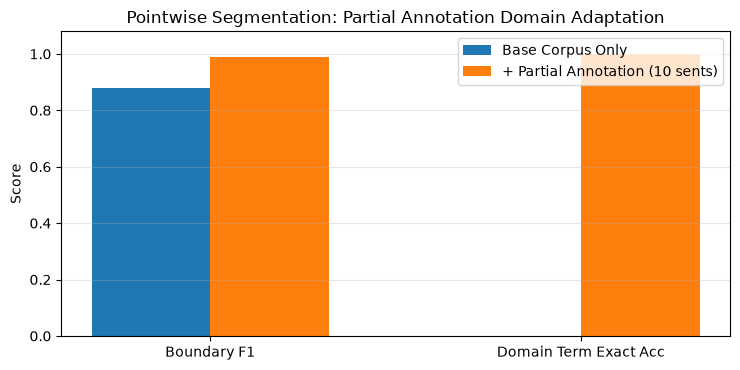


=== 点推定における周囲文脈による分割ゆれの例 ===
  新橋駅の近くで昼食を食べる。       -> 新橋 / 駅 / の / 近く / で / 昼食 / を / 食べる / 。
  木造の新橋が来月開通する。        -> 木造 / の / 新 / 橋 / が / 来月 / 開通 / する / 。
  病院で抗凝固薬を処方する。        -> 病院 / で / 抗凝固薬 / を / 処方 / する / 。
  新しい抗凝固薬だ。            -> 新しい / 抗凝固薬 / だ / 。


In [7]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support

base_segmented = [
    "わたし / は / 自然 / 言語 / 処理 / を / 学ぶ / 。",
    "これ / は / 新しい / 薬 / の / 説明書 / です / 。",
    "毎日 / 朝 / と / 夜 / に / 散歩 / する / 。",
    "東京 / 都内 / の / 病院 / で / 診察 / を / 受ける / 。",
    "医師 / が / 患者 / の / 症状 / を / 確認 / した / 。",
    "資料 / を / 読ん / で / 要点 / を / まとめる / 。",
    "新しい / 治療 / 方法 / が / 開発 / された / 。",
    "データ / を / 分析 / し / て / 結果 / を / 示す / 。",
    "学生 / が / 研究室 / で / 実験 / を / 行う / 。",
    "検査 / の / 数値 / を / グラフ / で / 確認 / する / 。",
    "安全 / な / 管理 / 体制 / を / 整える / 必要 / が / ある / 。",
    "専門 / の / 医師 / に / 相談 / する / こと / が / 大切 / だ / 。",
    "昨日 / の / 会議 / で / 次期 / 計画 / が / 決まっ / た / 。",
    "公園 / の / 橋 / を / 渡っ / て / 駅 / へ / 向かう / 。",
    "新橋 / 駅 / の / 近く / で / 昼食 / を / 食べる / 。",
    "木造 / の / 新 / 橋 / が / 来月 / 開通 / する / 。",
    "自然 / な / 表現 / を / 使っ / て / 文章 / を / 書く / 。",
    "統計 / 的 / な / 手法 / で / 予測 / 精度 / を / 測る / 。",
    "患者 / の / 状態 / を / 注意深く / 観察 / する / 。",
    "複数 / の / 病院 / が / 共同 / で / 調査 / を / 進める / 。",
]

def char_type(ch):
    if "\u4e00" <= ch <= "\u9fff":
        return "K"  # 漢字
    if "\u3040" <= ch <= "\u309f":
        return "H"  # ひらがな
    if "\u30a0" <= ch <= "\u30ff":
        return "A"  # カタカナ
    if ch.isascii() and ch.isalnum():
        return "E"  # 英数字
    return "S"      # 記号・境界

def extract_boundary_features(raw, pos):
    """文字間境界 pos (raw[pos-1] | raw[pos]) 周囲の文字・文字種 n-gram 素性"""
    padded = "^^" + raw + "$$"
    p = pos + 2
    feats = {}
    for off in [-2, -1, 0, 1]:
        ch = padded[p + off]
        feats[f"c{off}={ch}"] = 1.0
        feats[f"t{off}={char_type(ch)}"] = 1.0
    for off in [-2, -1, 0]:
        bg = padded[p + off:p + off + 2]
        feats[f"bg{off}={bg}"] = 1.0
        feats[f"tbg{off}={''.join(char_type(x) for x in bg)}"] = 1.0
    for off in [-2, -1]:
        feats[f"tg{off}={padded[p + off:p + off + 3]}"] = 1.0
    return feats

def parse_full_seg(seg_str):
    tokens = [t.strip() for t in seg_str.split("/") if t.strip()]
    raw = "".join(tokens)
    cuts, idx = set(), 0
    for tok in tokens[:-1]:
        idx += len(tok)
        cuts.add(idx)
    return raw, [(pos, 1 if pos in cuts else 0) for pos in range(1, len(raw))]

def parse_partial_seg(expr):
    """'|'=境界あり(1), '-'=境界なし(0) のみ抽出し、記号がない位置は未アノテーションとする"""
    raw_chars, labels = [], {}
    for ch in expr:
        if ch == "|":
            labels[len(raw_chars)] = 1
        elif ch == "-":
            labels[len(raw_chars)] = 0
        else:
            raw_chars.append(ch)
    return "".join(raw_chars), labels

# 部分的アノテーション例（着目する専門複合語の周囲数境界だけラベル付け）
partial_domain = [
    "患者に|抗-凝-固-薬|を処方した。",
    "診察で|心-房-細-動|が見つかった。",
    "術後に|せ-ん-妄|の症状が出た。",
    "看護で|じ-ょ-く-瘡|を予防する。",
    "検査で|磁-気-共-鳴|画像を見る。",
    "外来で|抗-凝-固-薬|の量を確認する。",
    "高齢者の|せ-ん-妄|を早期に発見する。",
    "長期入院で|じ-ょ-く-瘡|に注意する。",
    "医師が|心-房-細-動|と|抗-凝-固-薬|を説明した。",
    "画像診断で|磁-気-共-鳴|装置を使う。",
]

domain_test = [
    "新しい / 抗凝固薬 / が / 臨床 / で / 注目 / されている / 。",
    "心房細動 / の / 患者 / に / 抗凝固薬 / を / 使う / 。",
    "入院 / 中 / の / せん妄 / を / 防ぐ / ケア / が / 進む / 。",
    "じょく瘡 / の / 予防 / に / 定期 / 的 / な / 体位 / 変換 / を / 行う / 。",
    "病院 / の / 磁気共鳴 / 検査 / で / 異常 / を / 調べる / 。",
]
target_terms = ["抗凝固薬", "心房細動", "せん妄", "じょく瘡", "磁気共鳴"]

def train_pointwise_segmenter(full_segs, partial_list=None):
    X_dicts, y = [], []
    for seg in full_segs:
        raw, pairs = parse_full_seg(seg)
        for pos, lbl in pairs:
            X_dicts.append(extract_boundary_features(raw, pos))
            y.append(lbl)
    if partial_list:
        for expr in partial_list:
            raw, pmap = parse_partial_seg(expr)
            for pos, lbl in pmap.items():
                X_dicts.append(extract_boundary_features(raw, pos))
                y.append(lbl)
    dv = DictVectorizer()
    X = dv.fit_transform(X_dicts)
    clf = LogisticRegression(C=2.0, max_iter=1000, random_state=42).fit(X, y)
    return dv, clf, len(y)

def decode_pointwise(dv, clf, raw):
    if len(raw) <= 1:
        return [raw]
    feats = [extract_boundary_features(raw, pos) for pos in range(1, len(raw))]
    preds = clf.predict(dv.transform(feats))
    tokens, start = [], 0
    for pos, p in enumerate(preds, 1):
        if p == 1:
            tokens.append(raw[start:pos])
            start = pos
    tokens.append(raw[start:])
    return tokens

def evaluate_pointwise(dv, clf, test_segs):
    y_true, y_pred, term_hits = [], [], []
    for seg in test_segs:
        raw, pairs = parse_full_seg(seg)
        feats = [extract_boundary_features(raw, pos) for pos, _ in pairs]
        preds = clf.predict(dv.transform(feats))
        y_true.extend([lbl for _, lbl in pairs])
        y_pred.extend(preds.tolist())
        toks = decode_pointwise(dv, clf, raw)
        for term in target_terms:
            if term in raw:
                term_hits.append(int(term in toks))
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary")
    return p, r, f1, float(np.mean(term_hits))

dv_base, clf_base, n_base_b = train_pointwise_segmenter(base_segmented)
dv_part, clf_part, n_part_b = train_pointwise_segmenter(base_segmented, partial_domain)

eval_pw = []
for nm, dv, clf, nb_cnt in [
    ("ベース一般コーパスのみ", dv_base, clf_base, n_base_b),
    ("+ 部分的アノテーション (10文)", dv_part, clf_part, n_part_b),
]:
    p, r, f1, term_acc = evaluate_pointwise(dv, clf, domain_test)
    eval_pw.append({
        "訓練設定": nm,
        "学習境界数": nb_cnt,
        "境界 Precision": round(p, 3),
        "境界 Recall": round(r, 3),
        "境界 F1": round(f1, 3),
        "専門複合語 一致率": round(term_acc, 3),
    })

pw_df = pd.DataFrame(eval_pw)
print("=== ドメインテスト文（5文・専門複合語 6 箇所）での評価比較 ===")
display(pw_df)

seg_cmp = []
for seg in domain_test:
    raw, _ = parse_full_seg(seg)
    seg_cmp.append({
        "正解分割": seg,
        "ベースのみ予測": " / ".join(decode_pointwise(dv_base, clf_base, raw)),
        "部分アノテ適応後": " / ".join(decode_pointwise(dv_part, clf_part, raw)),
    })
display(pd.DataFrame(seg_cmp))

# 可視化
fig, ax = plt.subplots(figsize=(7.5, 3.8))
metrics_en = ["Boundary F1", "Domain Term Exact Acc"]
base_vals = [float(pw_df.iloc[0]["境界 F1"]), float(pw_df.iloc[0]["専門複合語 一致率"])]
part_vals = [float(pw_df.iloc[1]["境界 F1"]), float(pw_df.iloc[1]["専門複合語 一致率"])]
xp = np.arange(2)
w = 0.32
ax.bar(xp - w / 2, base_vals, w, label="Base Corpus Only")
ax.bar(xp + w / 2, part_vals, w, label="+ Partial Annotation (10 sents)")
ax.set_xticks(xp)
ax.set_xticklabels(metrics_en)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score")
ax.set_title("Pointwise Segmentation: Partial Annotation Domain Adaptation")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 同じ文字列でも周囲文脈によって境界判断が揺れる例（検索索引など一貫性重視用途の注意点）
print("\n=== 点推定における周囲文脈による分割ゆれの例 ===")
for s in [
    "新橋駅の近くで昼食を食べる。",
    "木造の新橋が来月開通する。",
    "病院で抗凝固薬を処方する。",
    "新しい抗凝固薬だ。",
]:
    print(f"  {s:20s} -> {' / '.join(decode_pointwise(dv_part, clf_part, s))}")

### 第 4 節のポイント

- **部分的アノテーションの手軽さと効果**: テスト文の `抗凝固薬`・`心房細動`・`せん妄`・`じょく瘡`・`磁気共鳴` に対し、一般コーパスのみの Pointwise モデルは 1 つも正しく切り出せませんでした（専門複合語一致率 **`0.000`**）。そこに、対象語の周囲わずか数境界だけに `|` / `-` を付けた部分的アノテーション 10 文（追加境界数は 53 境界のみ）を足して再学習すると、境界 F1 が **`0.879` → `0.988`**、専門複合語一致率が **`0.000` → `1.000`** へ劇的に改善します。
- **一貫性の注意点（関連論文 3章 8）**: Pointwise 予測は辞書引きや大域制約を使わず局所文脈だけで各境界を独立判定するため、「新橋駅」では `新橋 / 駅` と繋がるのに「新橋が」では `新 / 橋 / が` と分かれるように、同形文字列や未知語周辺の周囲文脈の違いで分割結果が揺れることがあります（全文検索の転置索引のように表記単位の一貫性が厳密に求められる用途では、辞書ベース解析の併用や後処理による統一に注意が必要です）。